# Lab 2: Classification Using KNN and RNN Algorithms

**Name:** Rahul Solanki
**Course:** MSCS-634-B01: Advanced Big Data and Data Mining
**Professor:** Satish Penmatsa
**Date:** November 8, 2026

## Step 1: Load and Prepare the Dataset

The Wine dataset ships with scikit-learn: 178 wines from three cultivars (class_0, class_1, class_2),
each described by 13 chemical measurements.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier, RadiusNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 200)

wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
df = wine.frame
print("Shape:", df.shape, "->", X.shape[1], "features + 1 target")
df.head()

Shape: (178, 14) -> 13 features + 1 target


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [2]:
# Feature details: type, range, and spread of every feature
details = X.describe().T[["mean", "std", "min", "max"]]
details.insert(0, "dtype", X.dtypes.astype(str))
details.round(2)

,dtype,mean,std,min,max
alcohol,float64,13.00,0.81,11.03,14.83
malic_acid,float64,2.34,1.12,0.74,5.80
ash,float64,2.37,0.27,1.36,3.23
alcalinity_of_ash,float64,19.49,3.34,10.60,30.00
magnesium,float64,99.74,14.28,70.00,162.00
total_phenols,float64,2.30,0.63,0.98,3.88
flavanoids,float64,2.03,1.00,0.34,5.08
nonflavanoid_phenols,float64,0.36,0.12,0.13,0.66
proanthocyanins,float64,1.59,0.57,0.41,3.58
color_intensity,float64,5.06,2.32,1.28,13.00


In [3]:
# Class distribution and missing values
counts = y.value_counts().sort_index()
dist = pd.DataFrame({"class": wine.target_names, "count": counts.values,
                     "percent": (100 * counts / counts.sum()).round(1).values})
print("Missing values in the whole table:", int(df.isna().sum().sum()))
dist

Missing values in the whole table: 0


,class,count,percent
0,class_0,59,33.1
1,class_1,71,39.9
2,class_2,48,27.0


**What the exploration shows:** no missing values, all 13 features are numeric, and the classes are moderately
unbalanced (class_1 is the largest at 39.9%). The features sit on very different scales: **proline** has a standard
deviation of about 315, **magnesium** about 14, and every other feature is below 4. This matters for both models,
because they classify by Euclidean distance.

In [4]:
# 80% training / 20% testing; stratify keeps the class proportions the same in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set:", X_train.shape, " Testing set:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts().sort_index(),
              "test": y_test.value_counts().sort_index()}).rename(index=dict(enumerate(wine.target_names)))

Training set: (142, 13)  Testing set: (36, 13)


,train,test
target,,
class_0,47,12
class_1,57,14
class_2,38,10


**Decision:** the features are used **unscaled** in Steps 2 and 3. The radius values the lab asks for (350 to 600)
only make sense in raw feature units; after z-score scaling, typical distances between wines are only 2 to 8.
The effect of scaling is checked separately at the end of Step 4.

## Step 2: Implement K-Nearest Neighbors (KNN)

In [5]:
k_values = [1, 5, 11, 15, 21]
n_test = len(y_test)

knn_rows = []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)        # Euclidean distance, equal votes
    knn.fit(X_train, y_train)
    acc = accuracy_score(y_test, knn.predict(X_test))
    knn_rows.append({"k": k, "accuracy": round(acc, 4), "correct": f"{round(acc * n_test)}/{n_test}"})

knn_results = pd.DataFrame(knn_rows)
knn_results

,k,accuracy,correct
0,1,0.7778,28/36
1,5,0.8056,29/36
2,11,0.8056,29/36
3,15,0.8056,29/36
4,21,0.8056,29/36


KNN reaches **0.806** (29 of 36 test wines) for k = 5, 11, 15 and 21, and **0.778** (28 of 36) for k = 1.
The whole range is a difference of a single test wine.

## Step 3: Implement Radius Neighbors (RNN)

In [6]:
radius_values = [350, 400, 450, 500, 550, 600]

rnn_rows = []
for r in radius_values:
    # outlier_label is a safeguard: a test wine with no training wine inside the radius
    # gets the most frequent class instead of raising an error (it never happens at these radii)
    rnn = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent")
    rnn.fit(X_train, y_train)
    acc = accuracy_score(y_test, rnn.predict(X_test))
    neighbors = rnn.radius_neighbors(X_test, return_distance=False)
    sizes = np.array([len(n) for n in neighbors])
    rnn_rows.append({"radius": r, "accuracy": round(acc, 4), "correct": f"{round(acc * n_test)}/{n_test}",
                     "avg neighbors": round(sizes.mean(), 1), "min neighbors": sizes.min(),
                     "no neighbors": int((sizes == 0).sum())})

rnn_results = pd.DataFrame(rnn_rows)
rnn_results

,radius,accuracy,correct,avg neighbors,min neighbors,no neighbors
0,350,0.7222,26/36,80.5,4,0
1,400,0.6944,25/36,87.9,9,0
2,450,0.6944,25/36,94.8,14,0
3,500,0.6944,25/36,100.1,17,0
4,550,0.6667,24/36,106.0,19,0
5,600,0.6667,24/36,111.0,23,0


RNN accuracy falls as the radius grows, from **0.722** (26 of 36) at radius 350 to **0.667** (24 of 36) at 550 and 600.
Every test wine has at least 4 neighbors, so no outlier labels were needed. At radius 600 the average vote already uses
111 of the 142 training wines, so the prediction moves toward "the most common class in a large region".

## Step 4: Visualize and Compare Results

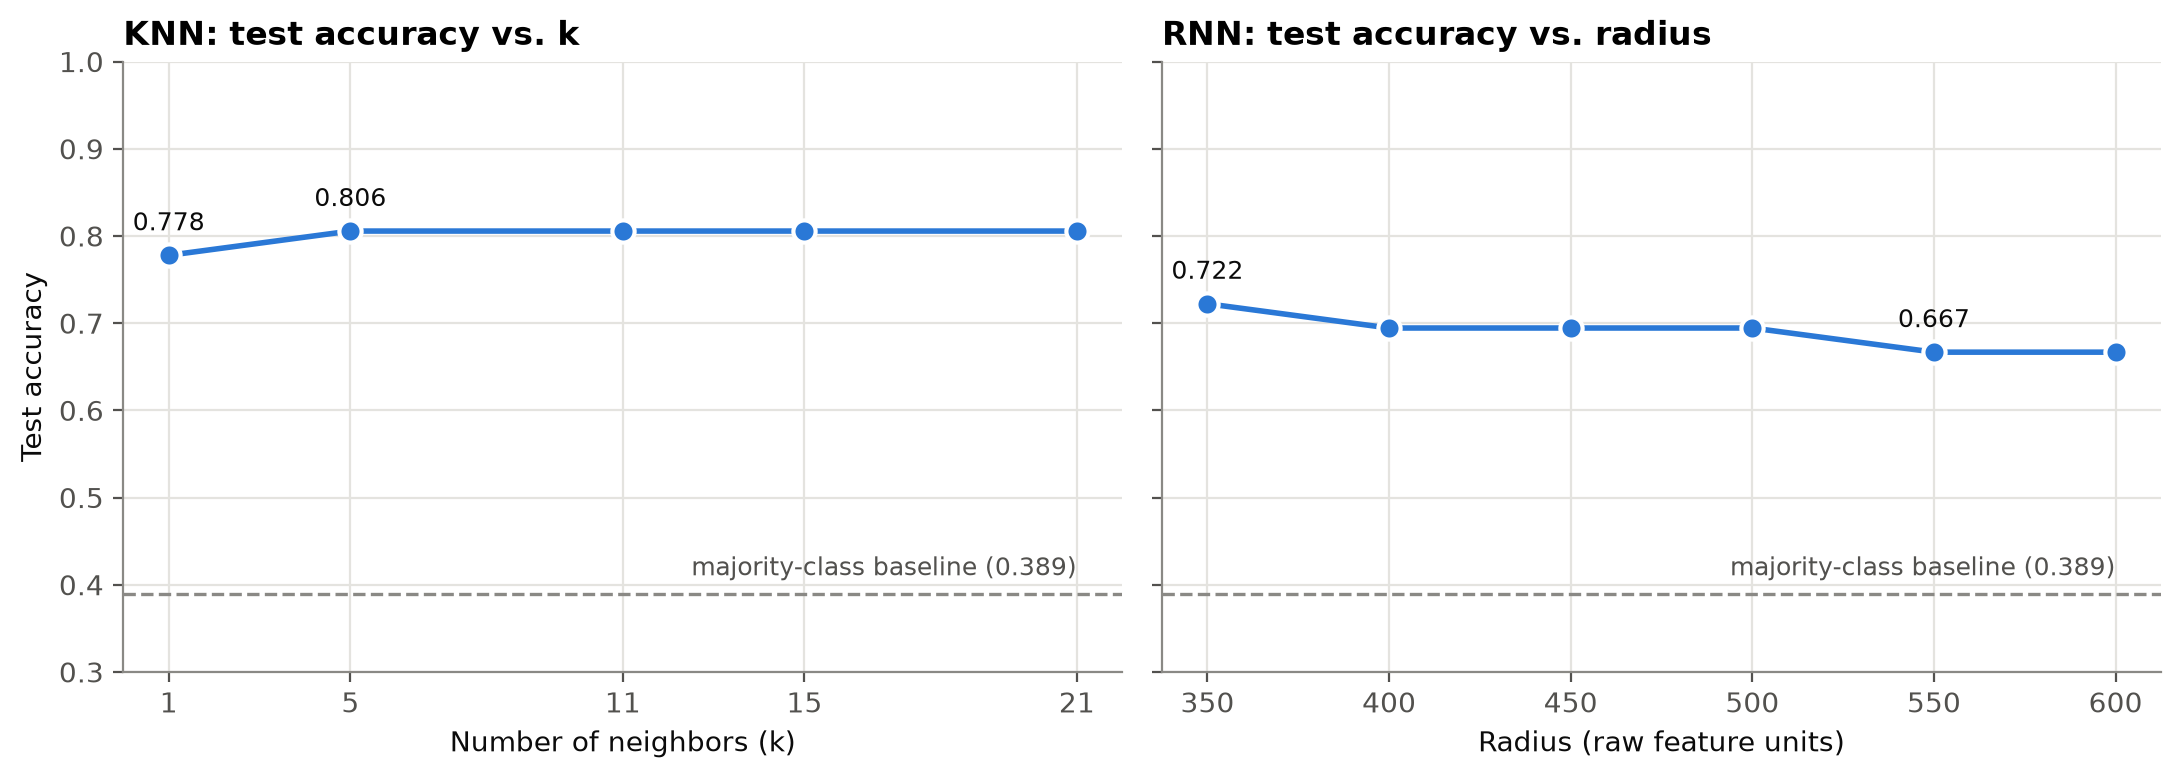

In [7]:
# Chart style: one series per plot, recessive grid, muted text
BLUE, GRAY, INK, MUTED = "#2a78d6", "#8a8985", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
                     "axes.titleweight": "bold", "font.size": 10})

baseline = y_test.value_counts().max() / n_test      # always guessing the largest class

def accuracy_plot(ax, res, xcol, title, xlabel):
    ax.plot(res[xcol], res["accuracy"], color=BLUE, lw=2, marker="o", ms=8, mec="white", mew=1.5, zorder=3)
    ax.axhline(baseline, color=GRAY, ls="--", lw=1.2)
    ax.text(res[xcol].iloc[-1], baseline + 0.015, f"majority-class baseline ({baseline:.3f})",
            ha="right", va="bottom", color=MUTED, fontsize=9)
    for idx in {res["accuracy"].idxmax(), res["accuracy"].idxmin()}:   # label best and worst only
        ax.annotate(f"{res.loc[idx, 'accuracy']:.3f}", (res.loc[idx, xcol], res.loc[idx, "accuracy"]),
                    textcoords="offset points", xytext=(0, 9), ha="center", color=INK, fontsize=9)
    ax.set_xticks(res[xcol])
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
accuracy_plot(axes[0], knn_results, "k", "KNN: test accuracy vs. k", "Number of neighbors (k)")
accuracy_plot(axes[1], rnn_results, "radius", "RNN: test accuracy vs. radius", "Radius (raw feature units)")
axes[0].set_ylabel("Test accuracy")
axes[0].set_ylim(0.3, 1.0)
fig.tight_layout()
plt.show()

In [8]:
# Best setting of each model and where its errors go
best_k = int(knn_results.loc[knn_results["accuracy"].idxmax(), "k"])
best_r = int(rnn_results.loc[rnn_results["accuracy"].idxmax(), "radius"])
best_knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_train, y_train)
best_rnn = RadiusNeighborsClassifier(radius=best_r, outlier_label="most_frequent").fit(X_train, y_train)

names = [f"true {c}" for c in wine.target_names]
cols = [f"pred {c}" for c in wine.target_names]
print(f"KNN, k = {best_k}: accuracy {accuracy_score(y_test, best_knn.predict(X_test)):.3f}")
display(pd.DataFrame(confusion_matrix(y_test, best_knn.predict(X_test)), index=names, columns=cols))
print(f"RNN, radius = {best_r}: accuracy {accuracy_score(y_test, best_rnn.predict(X_test)):.3f}")
display(pd.DataFrame(confusion_matrix(y_test, best_rnn.predict(X_test)), index=names, columns=cols))

KNN, k = 5: accuracy 0.806


,pred class_0,pred class_1,pred class_2
true class_0,12,0,0
true class_1,0,10,4
true class_2,0,3,7


RNN, radius = 350: accuracy 0.722


,pred class_0,pred class_1,pred class_2
true class_0,11,1,0
true class_1,0,14,0
true class_2,0,9,1


In [9]:
# Why accuracy is only around 70-80%: one feature decides the distance
from scipy.spatial.distance import pdist
share = pdist(X_train[["proline"]].values, "sqeuclidean").sum() / pdist(X_train.values, "sqeuclidean").sum()
print(f"Share of the squared Euclidean distance that comes from proline: {share:.1%}")
X.groupby(y.map(dict(enumerate(wine.target_names))))["proline"].agg(["mean", "min", "max"]).round(0)

Share of the squared Euclidean distance that comes from proline: 99.7%


,mean,min,max
target,,,
class_0,1116.0,680.0,1680.0
class_1,520.0,278.0,985.0
class_2,630.0,415.0,880.0


In [10]:
# Is the single split representative? Repeat both sweeps on 100 different stratified 80/20 splits
rows = []
for seed in range(100):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    for k in k_values:
        pred = KNeighborsClassifier(n_neighbors=k).fit(a_tr, b_tr).predict(a_te)
        rows.append(("KNN", f"k = {k}", accuracy_score(b_te, pred)))
    for r in radius_values:
        pred = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent").fit(a_tr, b_tr).predict(a_te)
        rows.append(("RNN", f"radius = {r}", accuracy_score(b_te, pred)))

repeat = pd.DataFrame(rows, columns=["model", "setting", "accuracy"])
repeat.groupby(["model", "setting"], sort=False)["accuracy"].agg(["mean", "std", "min", "max"]).round(3)

mean    std    min    max
model setting                                 
KNN   k = 1         0.759  0.065  0.583  0.889
      k = 5         0.691  0.064  0.528  0.833
      k = 11        0.692  0.063  0.556  0.833
      k = 15        0.701  0.061  0.556  0.833
      k = 21        0.712  0.063  0.583  0.861
RNN   radius = 350  0.669  0.044  0.583  0.750
      radius = 400  0.658  0.043  0.528  0.750
      radius = 450  0.648  0.041  0.556  0.722
      radius = 500  0.651  0.041  0.556  0.722
      radius = 550  0.642  0.043  0.528  0.722
      radius = 600  0.641  0.041  0.528  0.722

In [11]:
# Scaling check: z-score the features (fit on the training set only) and rerun both models
scaler = StandardScaler().fit(X_train)
Z_train, Z_test = scaler.transform(X_train), scaler.transform(X_test)

scaled_knn = pd.DataFrame([{"k": k, "accuracy": round(accuracy_score(
    y_test, KNeighborsClassifier(n_neighbors=k).fit(Z_train, y_train).predict(Z_test)), 4)} for k in k_values])

scaled_rnn_rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)     # sklearn warns when a test wine has no neighbors
    for r in [2, 2.5, 3, 3.5, 4, 5, 6]:            # radii in standard-deviation units
        m = RadiusNeighborsClassifier(radius=r, outlier_label="most_frequent").fit(Z_train, y_train)
        sizes = np.array([len(n) for n in m.radius_neighbors(Z_test, return_distance=False)])
        scaled_rnn_rows.append({"radius (z units)": r, "accuracy": round(accuracy_score(y_test, m.predict(Z_test)), 4),
                                "avg neighbors": round(sizes.mean(), 1), "no neighbors": int((sizes == 0).sum())})

print("KNN on standardized features"); display(scaled_knn)
print("RNN on standardized features"); display(pd.DataFrame(scaled_rnn_rows))

KNN on standardized features


,k,accuracy
0,1,0.9722
1,5,0.9722
2,11,1.0000
3,15,1.0000
4,21,1.0000


RNN on standardized features


,radius (z units),accuracy,avg neighbors,no neighbors
0,2.0,0.8611,1.5,16
1,2.5,0.9722,6.6,2
2,3.0,0.9722,15.2,1
3,3.5,1.0000,26.2,1
4,4.0,0.9444,38.7,0
5,5.0,0.8611,66.2,0
6,6.0,0.7500,101.2,0


### Observations and comparison

* **KNN beat RNN at every setting tried.** Best KNN = **0.806** (k = 5 to 21), best RNN = **0.722** (radius 350).
  Both are well above the 0.389 majority-class baseline.
* **KNN is flat across k on this split** (0.778 to 0.806, one test wine apart). Over 100 random splits, k = 1 is actually
  the best on average (0.759) and k = 5 to 21 sit at 0.69 to 0.71, so the ranking between k values on one 36-wine
  test set is mostly noise. A larger k smooths the vote, and here that slightly hurts because the classes overlap.
* **RNN gets worse as the radius grows** (0.722 to 0.667 on this split, 0.669 to 0.641 on average). A bigger radius
  pulls in more wines from other classes. At radius 600 the vote uses about 111 of the 142 training wines, and all 10
  class_2 test wines are labeled class_1.
* **Where the errors come from:** class_0 is almost always right because its proline is high (680 to 1680). class_1
  (278 to 985) and class_2 (415 to 880) overlap in proline, and proline supplies **99.7%** of the squared distance on
  unscaled data. So both models are effectively classifying on one feature. RNN suffers more: inside a wide fixed
  radius, class_1 (the largest class) outvotes class_2.
* **Scaling changes the picture.** With z-scored features, KNN reaches 0.972 to 1.000 and RNN reaches 0.972 to 1.000
  for radii 2.5 to 3.5 (one test wine still has no neighbors there and gets the fallback label). But RNN needs a new
  radius in new units: radius 2 leaves 16 of 36 test wines with no neighbors at all, and radius 6 drops back to 0.750.

### When to prefer KNN or RNN

* **KNN** is the safer default, as in this lab: every prediction uses exactly k neighbors, so it works in dense and
  sparse regions alike, and k is easy to tune because it does not depend on the units of the data.
* **RNN** suits data whose distances have a real meaning and a fairly even density, for example "wines within a known
  chemical tolerance". It can also flag points with no neighbors as outliers instead of forcing a label, which KNN
  cannot do. Its weakness, shown here, is that one fixed radius covers too much in dense regions, too little in sparse
  ones, and has to be re-chosen whenever the scaling changes.